<a href="https://colab.research.google.com/github/marijev838/TAA2/blob/main/TAA3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TAA3: Crop cover classification

In this tutorial we are going to explore the power of the **Google Earth Engine** through classifying crop categories on satelite imagery. In particular, we will focus on supervised classification using methods from frequentist statistics. Supervised classification refers to the process of using a training dataset with known labels to guide a mathematical classifier in the task of labeling spectral space. They key characteristic is that the training dataset guides (or “supervises”) the labeling.

The `Classifier` package within the **Google Earth Engine** handles supervised classification by traditional ML algorithms running in Earth Engine. We will use it for testing, but we will also teach you **Scikit-Learn**, the most commonly used ML package in Python. We will be looking at three classifiers, namely logistical regression, decision trees, and random forests. The workflow for classification is as follows:

    1. Collect training data. Assemble features which have a property that stores the known class label and properties storing numeric values for the predictors.
    2. Instantiate a classifier. Set its parameters if necessary.
    3. Train the classifier using the training data.
    4. Classify an image or feature collection.
    5. Estimate the classification error with independent validation data.
    6. Test the trained and validated classifier on new, unseen data

    
## Important before we start!
<hr>

⚠️**Questions are indicated in full bold face.** They should be filled in on Canvas, and we suggest explaining your rationale and thoughts, as they are intended to test your understanding of the ML pipeline.

⚠️ **Make sure that you copy this file before you continue**, else you will lose everything. To do so, go to Bestand/File and click on Een kopie opslaan in Drive/Save a Copy on Drive!

⚠️ **Partial use of AI is allowed**. You may use it to generate code, and to check your understanding of key concepts. **HOWEVER, don't use it to generate full answers to questions**.

## Learning Objectives
<hr>

- Understand how you can extract data from Google Earth Engine.
- Know how to visualize data from Google Earth Engine in Python.
- Understand and apply a supervised classification algorithm.
- Create training data and a simple classifier.
- Compare and judge the performance of a crop cover classification model.

P.S. we will <mark>mark</mark> important machine learning terminology so you can keep track of the most important terms.

## 1. Introducing the packages
<hr>

Within this tutorial, we are going to make use of the following main packages:

[**ee**](https://developers.google.com/earth-engine/guides/python_install) is a Python package to use the the Google Earth Engine.

[**geemap**](https://geemap.org/) is a Python package for interactive mapping with the Google Earth Engine.

[**scikit-learn**](https://scikit-learn.org/stable/) is a Python package for statistical learning that is built on the general NumPy ecosystem. It is the most-used package for classical machine learning.

Now we will import these packages in the cell below:

In [1]:
# Built-ins and standard packages
import os
import random
from datetime import datetime
from tqdm import tqdm # fancy progress bar package
from IPython.display import clear_output

# Data wrangling and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# EarthEngine
import ee
import geemap

# Machine learning packages and modules
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Performance metrics
from sklearn.metrics import accuracy_score, cohen_kappa_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

Finally, let's fix all of our random number generators. This will make our experiments reproducible.

In [2]:
### Set global seeds ###
seed = 123
np.random.seed(seed)
random.seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)

## 2.Accessing Sentinel-2 data from Google Earth Engine
<hr>

You will notice that you need to authorize ourselves to be able to use the Google Earth Engine. To do so, we will first have to register ourselves. on the website of the [Google Earth Engine](https://earthengine.google.com/). Here, make a project and remember the project ID.

Next, you will have to add it to your Colab notebook as a secret:
1. Cick the `key` button on the left-hand side of the Colab panel
2. Press *add new secret*
3. Allow notebook access, set the Name to `EE_PROJECT_ID`, and the Value to the name of your EE project ID.

Alternatively, you can authorize your project as follows, but then be aware that anyone observing the notebook can see your project name, which is potentially a security issue.

In [3]:
ee.Authenticate()
ee.Initialize(project="geodatasciencetaa3")

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Then, run the code below to load a basemap and to test if you set your credentials right. We will be using Flevoland as an example region, as it is agriculturally very diverse.

In [4]:
flevoland = ee.FeatureCollection('FAO/GAUL/2015/level1') \
    .filter(ee.Filter.eq('ADM0_NAME', 'Netherlands')) \
    .filter(ee.Filter.eq('ADM1_NAME', 'Flevoland'))

Map = geemap.Map(center=[52.5, 5.5], height=800, width=700, zoom=10, basemap='HYBRID')

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level1! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level1

  warnings.warn(warning, category=DeprecationWarning)


The code below loads and prepares Sentinel-2 SR imagery for the Flevoland region during the 2018 growing season. Sentinel-2 is part of the European Copernicus program and offers high-resolution multispectral data ideal for vegetation and crop cover analysis, and it has been operational for almost a decade now. Loading is done in the following steps:

1. Load Sentinel-2 SR imagery from the Earth Engine catalog.
2. Filter by location (flevoland) and date range (April–September 2018) to focus on the growing season.
3. Exclude cloudy images using a cloud cover threshold (< 20%).
4. Create a median composite to reduce noise and cloud artifacts.
5. Clip the composite to the Flevoland region.
6. Visualize and add to map

In [5]:
# Load Sentinel-2 SR imagery
sentinel = (ee.ImageCollection('COPERNICUS/S2_SR')
    .filterBounds(flevoland)
    .filterDate('2018-04-01', '2018-09-30')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
    .map(lambda img: img.select([
        'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12'
    ]).divide(10000))
)

# Create median composite and clip to Flevoland
sentinel_composite = sentinel.median().clip(flevoland)

# Visualization parameters (RGB)
vis_params = {
    'min': 0.0,
    'max': 0.3,
    'bands': ['B2', 'B3', 'B4'] # Add the bands you want to visualize here
}

Map.addLayer(sentinel_composite, vis_params, 'S2 RGB (2018)')
Map.centerObject(flevoland, 9)
Map

Map(center=[52.520525314862404, 5.595544502244546], controls=(WidgetControl(options=['position', 'transparent_…

In [6]:
# Load Sentinel-2 SR imagery
sentinel = (ee.ImageCollection('COPERNICUS/S2_SR')
    .filterBounds(flevoland)
    .filterDate('2018-04-01', '2018-09-30')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
    .map(lambda img: img.select([
        'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12'
    ]).divide(10000))
)

# Create median composite and clip to Flevoland
sentinel_composite = sentinel.median().clip(flevoland)

# Visualization parameters (RGB)
vis_params = {
    'min': 0.0,
    'max': 0.3,
    'bands': ['B3', 'B4', 'B8'] # Add the bands you want to visualize here
}

Map.addLayer(sentinel_composite, vis_params, 'S2 RGB (2018)')
Map.centerObject(flevoland, 9)
Map

Map(bottom=43385.0, center=[52.520525314862404, 5.595544502244546], controls=(WidgetControl(options=['position…

The values in each band are between 1 and 65,535, the 16-bit unsigned integer limit. The values represent the `surface reflection`, the fraction of light that is reflected at each pixel location.

❗**Q1 (2 points): The surface reflection values are stored as floating point values, rather than decimals, in order to save storage space. How many bytes does it take to store a single pixel in 16-bit uint, versus a signed 64-bit floating point value? Secondly, search online for which other techniques can be used to further reduce the storage-and transmission size of satellite images, and give a brief write-up of your findings here.**

❗**Q2 (1 point): Try to visualize the image with a false-colour composite using near-infrared, red, and green bands. Why are these bands are particularly important for the task at hand (crop mapping)? Discuss the spectral properties of the bands in your answers.**

Now that we have the image, let's add some indices to add some extra information for the model. Together with the raw spectral values, these will be our <mark>input variables</mark>, from which the model will learn how to fit to the reference values.

In [7]:
# NDVI: (NIR - Red) / (NIR + Red)
ndvi = sentinel_composite.normalizedDifference(['B8', 'B4']).rename('NDVI')

# Add indices to composite
image = sentinel_composite.addBands([ndvi])

❗**Q3 (1 points): Which other indices like the NDVI could be useful to add here, and why? Add at least one more to the image.**

In [ ]:
# EVI(2), RENDVI

In [8]:
# Define your own indices here

#EVI2: 2.5 * (NIR - Red) / (NIR + 2.4 * Red + 1)
evi2 = image.expression(
    '2.5 * (NIR - Red) / (NIR + 2.4 * Red + 1)',
    {
        'NIR': image.select('B8'),
        'Red': image.select('B4')
    }
).rename('EVI2')

# Add index to composite
image = image.addBands([evi2])

#RENDVI: (NIR - RedEdge) / (NIR + RedEdge)
rendvi = image.normalizedDifference(['B8', 'B5']).rename('RENDVI')

# Add index to composite
image = image.addBands([rendvi])

For the modelling, we will use reflectance from the optical and NIR bands (B2-B8), as well as the indices we derived.

⚠️ **Don't forget to add the indices you came up with here!**

In [9]:
# Use these bands for prediction
bands = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8']

# Add the names of the index bands
indices = ['NDVI', 'EVI2', 'RENDVI']

img_bands = [*bands, *indices]

In [10]:
Map.addLayer(evi2)
Map.centerObject(flevoland, 9)
Map



Map(bottom=43385.0, center=[52.52052531486237, 5.595544502245036], controls=(WidgetControl(options=['position'…

## 3. Create reference data from agricultural data

Now that we have had a look at the images we will be working with, we can define the <mark>reference data</mark> (also referred to as *labelled data* and *ground truth* data) that we're going to use to train classification models. The training data is used to <mark>fit</mark> models. A fitted or trained models can then be used to predict on a new dataset to determine how well it works on unseen data.

For example, crop type training data will contain examples of each class in the study’s legend. Based on these labels, the classifier can predict the most likely crop type for each pixel in an image. This is an example of a categorical classification and the training labels are therefore categorical. By contrast, a continuous variable (e.g. percent tree cover) can be predicted using continuous training labels.

There are several ways you can create a region to fence off your dataset:

- Draw a shape (e.g., rectangle) on the map and the use `region = Map.user_roi`
- Define a geometry, such as `region = ee.Geometry.Rectangle([-122.6003, 37.4831, -121.8036, 37.8288])`
- Create a buffer zone around a point, such as `region = ee.Geometry.Point([-122.4439, 37.7538]).buffer(10000)`
- If you don't define a region, it will use the image footprint by default

In our case, we use the complete extent of the image for training and evaluating our models, which in the default case is cropped to Flevoland already.

Our reference data is the EUCROPMAP dataset, a pan-European dataset made from a combination of sensor acquisitions and in-situ reference data. Fortunately, we can use GEE to directly access the data.

In [11]:
# Load and clip EUCROPMAP 2018
cropmap = ee.ImageCollection('JRC/D5/EUCROPMAP/V1') \
    .filterDate('2018-01-01', '2019-01-01') \
    .first() \
    .clip(flevoland)

In [12]:
# Add layer
Map.addLayer(cropmap, {}, 'EUCROPMAP 2018')
Map.centerObject(flevoland, 9)

legend_dict = {
    "Artificial": "#ff130f",     # 100
    "Common wheat": "#a57000",   # 211
    "Durum wheat": "#896054",    # 212
    "Barley": "#e2007c",         # 213
    "Rye": "#aa007c",            # 214
    "Oats": "#a05989",           # 215
    "Maize": "#ffd300",          # 216
    "Rice": "#00a8e2",           # 217
    "Triticale": "#d69ebc",      # 218
    "Other cereals": "#d69ebc",  # 219
    "Potatoes": "#dda50a",       # 221
    "Sugar beet": "#a800e2",     # 222
    "Other root crops": "#00af49",  # 223
    "Other non-permanent industrial crops": "#00af49",  # 230
    "Sunflower": "#ffff00",      # 231
    "Rapeseed and turnip rapeseed": "#d1ff00",  # 232
    "Soya": "#267000",           # 233
    "Dry pulses": "#f2a377",     # 240
    "Fodder crops (cereals and leguminous)": "#e8bfff",  # 250
    "Bare arable land": "#696969",  # 290
    "Woodland and Shrubland (incl. permanent crops)": "#93cc93",  # 300
    "Grasslands": "#e8ffbf",     # 500
    "Bare land/lichens moss": "#a89e7f",  # 600
    "Water": "#0793de",          # 700
    "Wetlands": "#7cafaf",       # 800
}

# Add legend to map
Map.add_legend(title='EUCROPMAP 2018', legend_dict=legend_dict)
Map


Map(bottom=43385.0, center=[52.520525314862404, 5.595544502244546], controls=(WidgetControl(options=['position…

Let's visualize the classes, with text labels

While the non-crop classes are quite detailed, they contain a lot of uncertainty, and they are difficult for a model to learn. Instead, let's first generalize the crop cover classes to the second level of the hierarchy for these. For this, we will finish the following function that we will apply to the column.

In [13]:
def reclassify_cropmap(img):
    # Define second-level hierarchy codes
    cereals = img.gte(210).And(img.lt(220))       # 21x
    root_crops = img.gte(220).And(img.lt(230))    # 22x
    industrial_crops = img.gte(230).And(img.lt(240))  # 23x
    leguminous_crops = img.eq(240)                # 24x
    fodder_crops = img.eq(250)                    # 25x
    bare_arable = img.eq(290)                     # 29x

    # Apply mapping
    img = img.where(cereals, 210)
    img = img.where(root_crops, 220)
    img = img.where(industrial_crops, 230)
    img = img.where(leguminous_crops, 240)
    img = img.where(fodder_crops, 250)
    img = img.where(bare_arable, 290)

    # Mask out non-agricultural pixels (i.e., outside 200–299 range)
    # agri_mask = img.gte(200).And(img.lt(300))
    return img #img.updateMask(agri_mask)

# Apply reclassification
reclassified_cropmap = reclassify_cropmap(cropmap)

Now we are going to make the training dataset. We do so by randomly sampling pixels from the image array that coincide with a reference pixel.

In the `sample()` function, we have to specify multiple arguments:

- Through the `region`argument we specify the geographic boundary of our training dataset.
- Through the `scale` argument we specify the size of the points for our sample (10 would indicate 10m).
- Through the `numPixels` argument we specify how many pixels we want to extract. More pixels means more training time needed, but a higher expected accuracy. Wouldn't recommend setting this to more than 25k.
- Through the `seed` argument we specify which random selection order we want. Through using a seed, you can always reproduce your results.
- Through the `geometries` argument we specify whether we want to extract the geometries as well. In most cases you want to retain the geometry, so specify `true`.

In [14]:
reference_points = reclassified_cropmap.sample(
    **{
        'region': flevoland,
        'scale': 10,
        'numPixels': 25000,
        'seed': 0,
        'geometries': True,
    }
)

Let's see if that worked, and what our class histogram is like now...

In [15]:
# Count the number of samples per class
class_counts = reference_points.aggregate_histogram('classification').getInfo()
for class_id, count in class_counts.items():
    print(f"Class {class_id}: {count} samples")

Class 100: 15 samples
Class 210: 7189 samples
Class 220: 4720 samples
Class 230: 228 samples
Class 240: 584 samples
Class 250: 30 samples
Class 290: 134 samples
Class 300: 4194 samples
Class 500: 3839 samples


Let's check how many points we got for our sample set, and which information a single point contains.

In [16]:
print("total number of points:", reference_points.size().getInfo())
print(reference_points.first().getInfo())

total number of points: 20933
{'type': 'Feature', 'geometry': {'type': 'Point', 'coordinates': [5.718155243128937, 52.74586375592199]}, 'id': '0', 'properties': {'classification': 210}}


Take note of the final column, the *'classification'* property. It contains the crop cover associated with each individual pixel. Try looking up some information about it to understand what it is that we are trying to classify. [Have a look at the documentation.](https://developers.google.com/earth-engine/datasets/catalog/JRC_D5_EUCROPMAP_V1)

Great! Now that we have a dataset of reference points defined, we can split them into bins, which we can train and evaluate models on.

## 4.Split dataset into folds
<hr>

In the previous step we made our co-located dataset consisting of crop cover reference data and Sentinel-2 pixels with additional calculated values. The next step is to partiton the dataset into training and validation splits, so that we can train and evaluate models. In short, the <mark>training split</mark> is used for a model to fit to the input data, while the <mark>validation split</mark> is used to test if the learned model can predict well on new, unseen data.

 Later in the notebook there will also be a <mark>test split</mark> on which we evaluate the final performance of models.

In [17]:
# This property of the table stores the reference info
label_col = 'classification'

# Sample points for validation / training split datasets
sample = reference_points.randomColumn();
training_sample = sample.filter('random <= 0.8');
validation_sample = sample.filter('random > 0.8');

train_data = image.select(img_bands).sampleRegions(
    **{'collection': training_sample, 'properties': [label_col], 'scale': 10}
)

val_data = image.select(img_bands).sampleRegions(
    **{'collection': validation_sample, 'properties': [label_col], 'scale': 10}
)

❗**Q4 (4 points): When using a 80/20 randomized split for training/validation, we will produce a model that isn't trained to predict well in new and unseen regions. Why is this the case? Secondly, what should we take into account when selecting regions to use as a hold-out set if we were to do geographical stratification (i.e. using a new region as validation dataset)?**

In [ ]:
# 1.                  2.

In [18]:
print(img_bands)

['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'NDVI', 'EVI2', 'RENDVI']


Finally, let's visualize a single image pixel to make sure that everything is included as expected. Contrary to what some might say, preparing and organizing your dataset takes up the bulk of your time when working with machine learning models.

⚠️ **Always double-check your dataset before training, or you'll find yourself wasting a lot of time**!

In [19]:
# Print the first feature in the training collection
print(train_data.first().getInfo())

{'type': 'Feature', 'geometry': None, 'id': '0_0', 'properties': {'B2': 0.041600000113248825, 'B3': 0.07509999722242355, 'B4': 0.06689999997615814, 'B5': 0.13519999384880066, 'B6': 0.2574999928474426, 'B7': 0.3122999966144562, 'B8': 0.34599998593330383, 'EVI2': 0.46314117687595024, 'NDVI': 0.6759505867958069, 'RENDVI': 0.43807148933410645, 'classification': 210}}


As can be seen, each datapoint contains reflectance values from the S2 image, the indices we defined, and a crop cover reference label.

#### Converting to scikit-learn compatible data
The GEE package provides built-in functions for a couple of popular models, so in principle we can continue working entirely within GEE. However, we're interested in teaching you re-usable machine learning skills. Therefore, we run our models using scikit-learn, Python's most popular package for standard ML models. For this purpose, we should convert our data into a data structure that is compatible with this package.

In [20]:
def feature_collection_to_lists(features, input_features, label_col):
  # Convert data to Pandas for use with scikit
  features_list = features.toList(features.size()).getInfo()
  features_list = [feature['properties'] for feature in features_list] # Unpack from dictionary
  features_df = pd.DataFrame(features_list)

  inputs = features_df[input_features] # Image pixel values for training
  labels = features_df[label_col] # Crop cover values for validation
  return inputs, labels

x_train, y_train = feature_collection_to_lists(train_data, img_bands, label_col)
x_val, y_val = feature_collection_to_lists(val_data, img_bands, label_col)

Take note of the nomenclature - `x_train` contains our *independent variables* (spectral bands and indices), and `y_train` is our *dependent variable* (the crop class we want to predict)

## 5. Training models
<hr>

Now that we have our dataset split into training, validation, and testing samples, we can begin training models. But wait up! Before we start throwing increasingly sophisticated models at the problem, we have to understand how statistical learning works in the first place. We'll consider a number of frequentist statistical models of increasing complexity. We'll first take a look at a basic model, namely logistical regression. Next, we consider decision trees, and finally we consider a more sophisticated tree-based classifier, namely random forest models.

### 5a. Logistic Regression
---
Let's first consider what is possibly the simplest approach in frequentist statistics for this task - <mark>Logistic Regression</mark>. Similar to a *Linear Regression* model, a logistic regression model fits each of the input features to the reference data based on the total set of datapoints in the training dataset. It outputs the probability that a given datapoint belongs to a given label class, e.g. the probability that a given sample belongs to the `urban fabric` class. It creates a distinct *'S-shaped'* probability distribution, courtesy of the sigmoid function used to bound it.

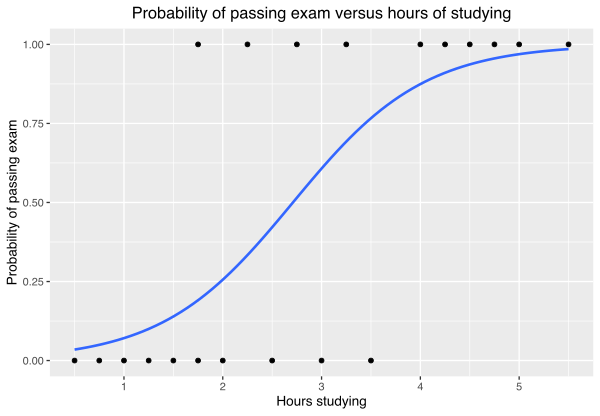

(Image courtesy of Wikimedia)

❗**Q5 (4 points): Explain that a logistic prediction is a special case of a linear regression. Specifically, explain what the dependent variables of the linear regression are when using it for classification in a logistic regression (HINT: a Sigmoid operation transforms a number)**

Let's fit the model to our training data and evaluate how well it performs on the training split using a straightforward overall accuracy measures, where we simply count the ratio of correct positives. Under the hood, we assign a `1` or a `0` to each class, which we call <mark>one-hot encoding</mark> (as in - only one of the labels is *hot*, with a value of `1`). The model is then optimized to predict a confidence for each class separately which indicates if the given class is present or not. In the scikit implementation, the most confident class (closest to `1`) gets assigned to the datapoint. Let's try it out!

In [21]:
# Train a logistic regression model
model = LogisticRegression()
model.fit(x_train.values, y_train.values)

# Predict and evaluate
train_y_pred = model.predict(x_train)
train_accuracy = accuracy_score(train_y_pred, y_train)
print("Training accuracy:", round(train_accuracy, 3))

Training accuracy: 0.604


Okay, that's reasonably good. But is it better than random guessing? For this, we use Cohen's Kappa. The **Kappa Coefficient** is generated from a statistical test to evaluate the accuracy of a classification. **Kappa** essentially evaluates how well the classification performed as compared to just randomly assigning values, i.e. did the classification do better than random. The **Kappa Coefficient** can range from -1 to 1. A value of 0 indicated that the classification is no better than a random classification. A negative number indicates the classification is significantly worse than random guessing. A value of to 1 indicates that the predicted values are equal to the ground truth, therefore not being the product of any random guessing.

By the way, in professional parlay, we refer to measures as the `accuracy` and `Cohen's Kappa` as <mark>performance metrics</mark>.

In [22]:
train_kappa = cohen_kappa_score(train_y_pred, y_train)
print("Training Kappa:", round(train_kappa, 3))

Training Kappa: 0.458


Looking good. It's not a perfect performance, but the model outperforms random guessing by a significant margin. Not bad for the simplest possible model with a fairly large number of target classes.

Now, let's see if it manages to predict well on pixels which it hasn't been trained for.

In [23]:
val_y_pred = model.predict(x_val)

val_accuracy = accuracy_score(y_val, val_y_pred)
print("Validation accuracy:", round(val_accuracy, 3))

val_kappa = cohen_kappa_score(val_y_pred, y_val)
print("Validation Kappa:", round(val_kappa, 3))

Validation accuracy: 0.625
Validation Kappa: 0.484


❗**Q6 (3 points): Say that you have a binary positive/negative prediction problem, where 90% of the samples in your dataset are negative. What might happen to a model trained on this dataset? How would that be reflected in the accuracy and Cohen's Kappa scores? How would you use these metrics to test if the model is fit for purpose?**

Before we move on, let's make two quick functions that we can re-use whenever we want to evaluate our models quickly. It will save us a lot of code re-use when iterating through candidate models.

In [24]:
def train_model(model, training_x, training_y):
    """
    Make a training that does the following:
    1. Trains a model based on dependent (y) & independent variables (x)
    2. Predicts new values for the given training set
    3. Compute and print metrics (Kappa and Accuracy)
    4. Return the trained model at the end of the function
    """

    model.fit(training_x.values, training_y.values)

    train_y_pred = model.predict(training_x)

    accuracy = accuracy_score(training_y, train_y_pred)
    print("Accuracy:", round(accuracy, 3))

    kappa = cohen_kappa_score(training_y, train_y_pred)
    print("Kappa:", round(kappa, 3))

    return model


def validate_model(model, validation_x, validation_y):
    """
    Make a function based on what you've seen above that does the following:
    1. Predicts new values for the given validation set
    2. Compute and print metrics (Kappa and Accuracy)
    """

    val_y_pred = model.predict(validation_x)

    val_accuracy = accuracy_score(validation_y, val_y_pred)
    print("Validation accuracy:", round(val_accuracy, 3))

    val_kappa = cohen_kappa_score(validation_y, val_y_pred)
    print("Validation Kappa:", round(val_kappa, 3))

### 5b. Decision tree classifiers
---
Now that we have some experience with the simplest possible approach, let's talk about models which are a bit more clever - tree-based classfiers. First, we'll take a look at a standard <mark>decision tree model</mark>. It learns the best places to cut off the data to create the best separation between classes. As such, contrary to a logistic regression, a decision tree can approximate complex decision boundaries. Graphically, classification trees identify lines that successively split the data space to separate the training points into their classes, as shown below.

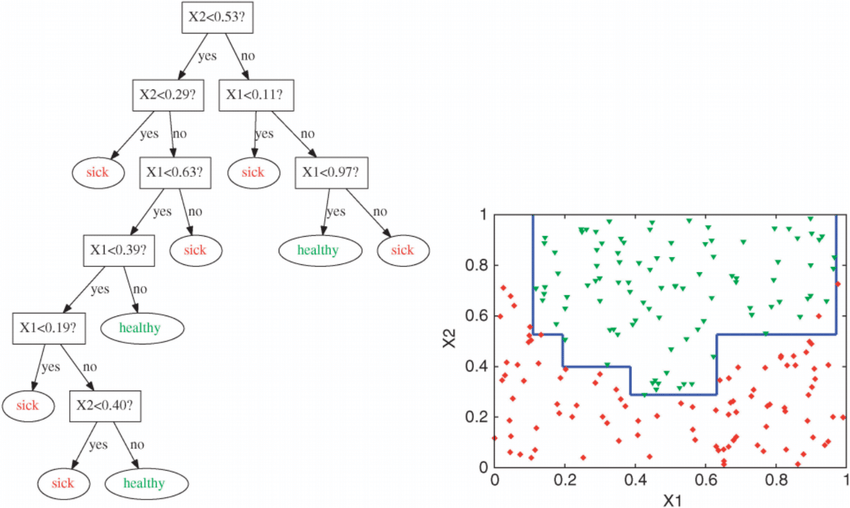

([Image courtesy of Clayton Miller](https://www.researchgate.net/publication/313720565_Screening_meter_data_Characterization_of_temporal_energy_data_from_large_groups_of_non-residential_buildings))

Let's repeat the process of training a model by using a decision tree classifier. This is a <mark>parametrized</mark> model, which means that there are certain decisions to make, which will affect the performance of the model. First, let's run it with the default settings, and you'll quickly see why it's important to pay attention to the parameters of your models.

In [25]:
decision_tree_model = DecisionTreeClassifier()
decision_tree_model = train_model(decision_tree_model, x_train, y_train)
validate_model(decision_tree_model, x_val, y_val)

Accuracy: 1.0
Kappa: 1.0
Validation accuracy: 0.568
Validation Kappa: 0.428


This results in a very big contrast in the model's performance. How can it be that the model performs perfectly on the training dataset, but doesn't do as well on the validation dataset? For the answer, [take a look at the documentation of the model](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html). In particular, look at the parameters `max_depth` and `min_samples_split`. Use the docs and any other means at your disposal to answer the following question.

❗**Q7 (2 points): What would happen if we set `max_depth` to the same size as the number of training samples that we have?**

In [ ]:
# The MaxDepth is a parameter that influences the 'depth' or 'length' of the tree from the root, being the first node, to the last leaf of the tree. When using a tree that is too long, so with a MaxDepth value that is too high, the model will use too many nodes as decision points and this will cause overfitting. When this happens, the model becomes too complex and is primarily focussing on fitting the training data in the tree, including for instance the noise in that data, instead of being trained to accurately assess unseen data. This is exactly what will happen when the Maxdepth equals the number of training samples.

So now that we know about parameters, let's try setting these two parameters such that the model doesn't become hyper-specialized on the training dataset, at the cost of performance on unseen data. Experiment with different parameter settings in the code box below.

In [64]:
decision_tree_model = DecisionTreeClassifier(min_samples_split=5, max_depth=10)
decision_tree_model = train_model(decision_tree_model, x_train, y_train)
validate_model(decision_tree_model, x_val, y_val)

Accuracy: 0.705
Kappa: 0.603
Validation accuracy: 0.647
Validation Kappa: 0.522


In [88]:
decision_tree_model = DecisionTreeClassifier(min_samples_split=4, max_depth=(10))
decision_tree_model = train_model(decision_tree_model, x_train, y_train)
validate_model(decision_tree_model, x_val, y_val)

Accuracy: 0.706
Kappa: 0.604
Validation accuracy: 0.648
Validation Kappa: 0.523


In [26]:
decision_tree_model = DecisionTreeClassifier(
    min_samples_split=4,
    max_depth=10,
    random_state=42
)

decision_tree_model = train_model(
    decision_tree_model,
    x_train,
    y_train
)

validate_model(
    decision_tree_model,
    x_val,
    y_val
)

Accuracy: 0.706
Kappa: 0.604
Validation accuracy: 0.649
Validation Kappa: 0.524


❗**Q8 (1 point): Report the settings of the best-performing model on the validation dataset, along with the validation accuracy and Kappa. Which parameters did you adjust, and why? Did it have a positive effect?**

In [ ]:
# The best-performing decision tree classifier model has a minimum sample split of 4 and a MaxDepth of 10. This provides the following (validation) accuracy and kappa:
""""
Accuracy: 0.706
Kappa: 0.604
Validation accuracy: 0.649
Validation Kappa: 0.524

Apparently, the MapDepth of the tree with 10 was ideal. In most cases the depth of a tree is between 3 and 10 and by lowering the value, the accuracies and kappa values dropped. When using a minimum sample split of 4, the model produces a slightly higher validation accuracy and kappa when using a higher or lower number.

### 5c. Random Forests
---

> *Do you know what is better than one tree? Two trees! And what is better than two trees? A forest!*

*Tin Kam Ho, inventor of Random Forest models, 1995* (probably).

While the quote above is a tongue-in-cheek fake quote, the author of <mark>Random Forest (RF)</mark> models clearly was onto something. What if we use multiple of decision trees, then take their average prediction? This is an <mark>ensemble</mark> approach, where the rationale is that we can achieve a better performance by averaging multiple prediction models. In the case of RF, we ensemble individual decision trees to produce trees which have slightly different prediction characteristics.

This intuitive approach has been a mainstay of machine learning for remote sensing for decades, with good performance even on small datasets. In fact, up until very recently they were still preferred over sophisticated deep learning model for niche tasks with a small amount of datapoints, due to their ease of use and efficiency! Bigger is certainly not always better. So let's try them out!

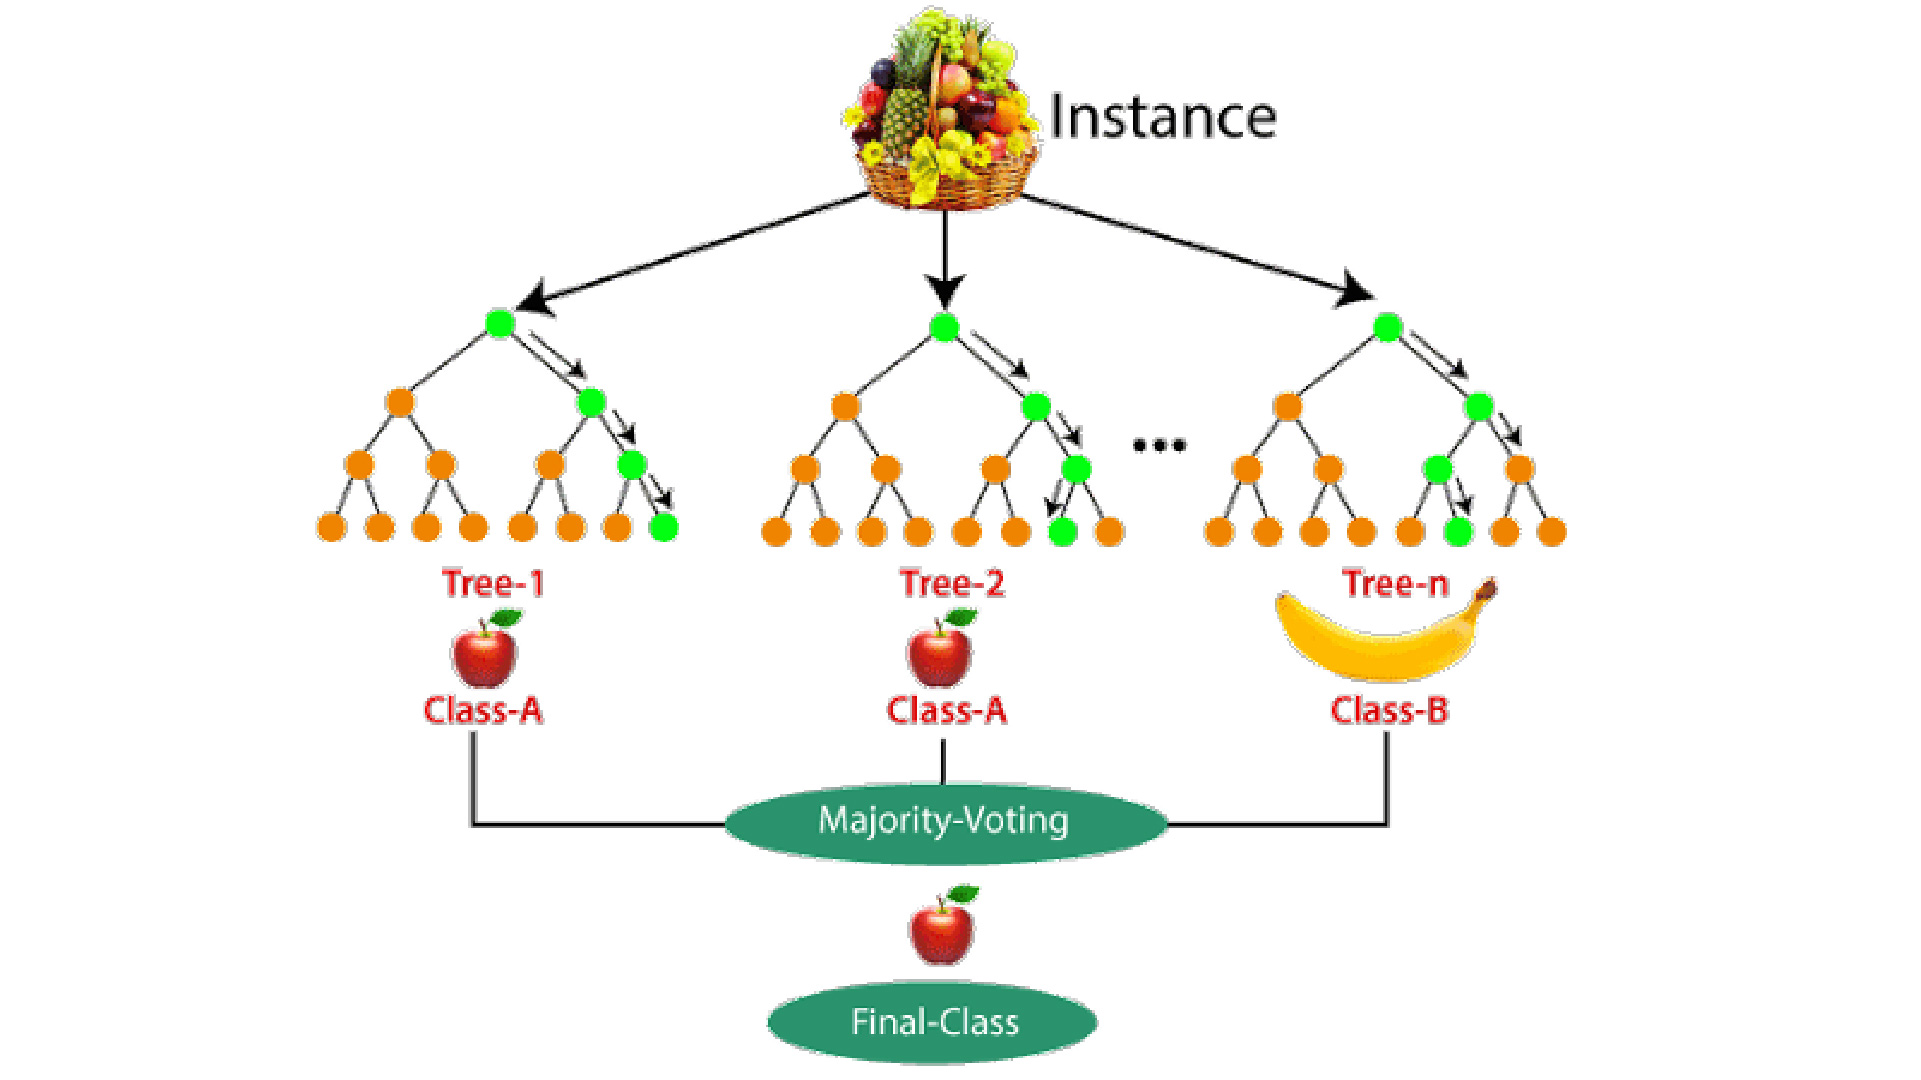

([Courtesy of Sruthi E.R.](https://www.analyticsvidhya.com/blog/2021/06/understanding-random-forest/))

For the below two questions, [have a look at sections 8.1 and 8.2 of ISLR](https://www.stat.berkeley.edu/users/rabbee/s154/ISLR_First_Printing.pdf) to better understand the theory and implementation of tree-based models.

❗**Q9 (2 point): Why are tree-based models capable of handling categorical data without adaptations such as the Sigmoid transformation?**

❗**Q10 (2 point): Random forest models belong to a family of models known as ensemble models. Each model in an ensemble should predict differently from one another, otherwise it's simply the same predictive model copied many times over. What is the adaptation that ensures that individual decision trees in a random forest ensemble model each predict slightly differently from one another?**

[First, take a look at the documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), where you'll see that (logically) it is a parametrized model too. To keep it simple, let's focus on two important parameters while fixing the rest. We focus on `min_samples_split`, and `n_estimators`. You know the first one, and by its name you can reasonably figure out that `n_estimators` is the number of trees we'd like to use.

Rather than guessing which parameters are best like we did before, we will write a function that will help us to find the best parameters based on a <mark>grid search</mark>. With a grid search optimization approach, we iterate over all combinations of parameters to find the best one of the set.

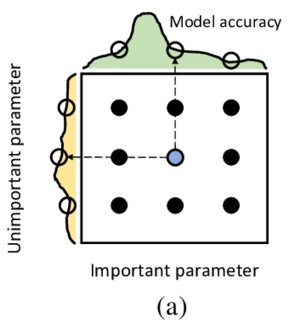

(A visual example of grid search, where parameter searching occurs in a grid with regular intervals. Adapted from [Pilario, Cao, and Shafiee](https://www.researchgate.net/publication/341691661_A_Kernel_Design_Approach_to_Improve_Kernel_Subspace_Identification))

In [27]:
# RF Parameter choices. Change them as you see fit.
n_estimator_ranges = [10, 25, 50, 100, 250]
min_sample_ranges = [2, 5, 10, 25, 50]
total_combinations = len(n_estimator_ranges) * len(min_sample_ranges)

The following loop goes through all of the parameter combinations to measure their performance. In a nutshell, the code below performs the following steps:


1.   Instantiate two matrices, one for tracking performance, the other for time taken
2.   Iterate over the number of trees in the outer loop (estimators)
3.   Iterate over the number of splits per sample in the inner loop
4.   In the inner loop, we train our model on the dataset, measure time taken and performance, and insert these in the matrices

It can take a minute or two to complete running, so have a sip of coffee and wait patiently - after you finish filling in the code to complete it!

In [28]:
## Instantiate performance and time-keeping matrices
kappa_paramsearch = np.ndarray([len(n_estimator_ranges), len(min_sample_ranges)])
time_paramsearch = np.ndarray([len(n_estimator_ranges), len(min_sample_ranges)])

# Time-keeping function to track if the code runs correctly.
pbar = tqdm(total=total_combinations)

## Perform the parameter searching and keep track of performance/time
## We loop over all possible combinations of both parameters
for n_trees_index, n_trees in enumerate(n_estimator_ranges):
    for min_leaves_index, min_samples in enumerate(min_sample_ranges):
        ## Update our time keeping function
        pbar.set_description(f"n_trees: {n_trees}, min_leaves: {min_samples}")

        ## Initialize the random forest classifier
        model = RandomForestClassifier(n_estimators=n_trees, min_samples_split=min_samples, max_depth=25)

        ## Fit the classifier to the training data/labels and measure time taken
        start = datetime.now()
        model.fit(x_train.values, y_train.values)
        end = datetime.now()
        time_taken = float(f"{(end - start).seconds}.{round((end - start).microseconds, 2)}")

        ## Use the model to predict all of the validation pixels
        val_y_pred = model.predict(x_val)
        val_kappa = cohen_kappa_score(val_y_pred, y_val)

        ## Store accuracies and time taken for this parameter combination
        kappa_paramsearch[n_trees_index, min_leaves_index] = round(val_kappa, 3)
        time_paramsearch[n_trees_index, min_leaves_index] = round(time_taken, 3)

        pbar.update()

# Clear the progress bar print(s) once it's done running
clear_output()

Let's have a look at which parameter combination provides the best performance, and how long it took to run each model.

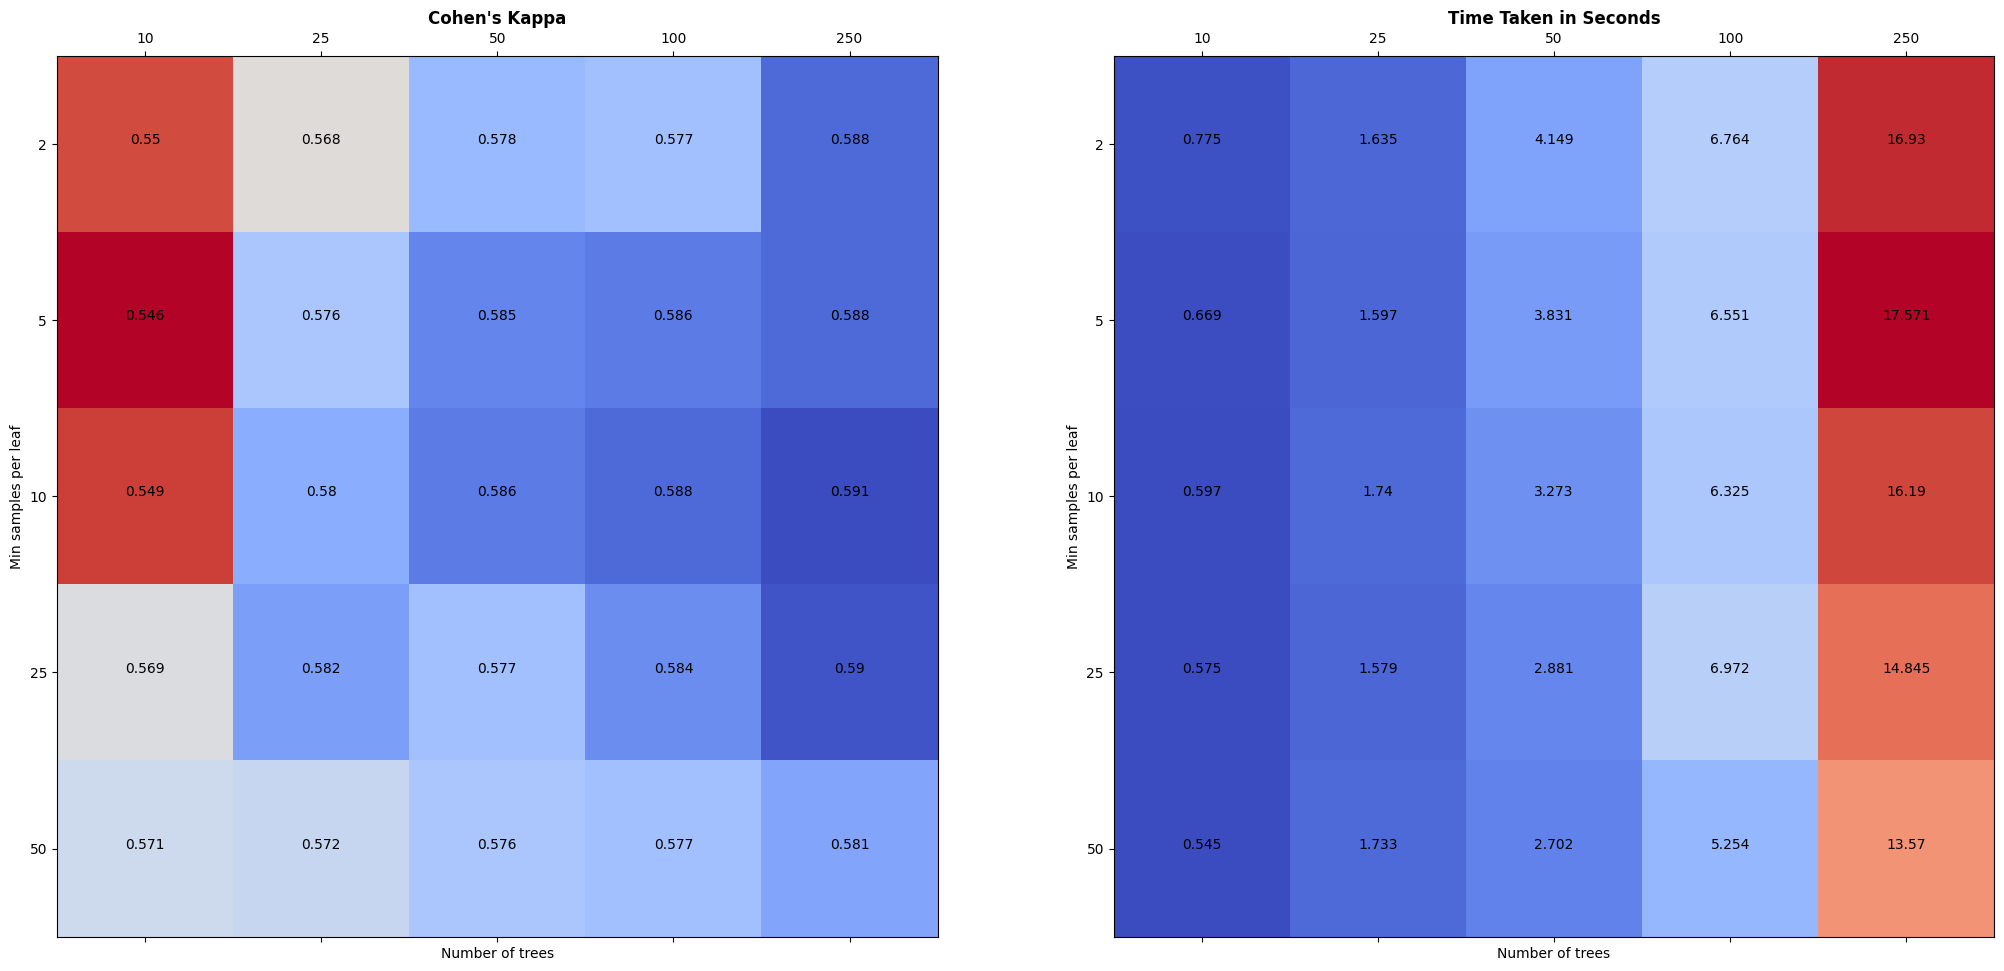

In [29]:
## Dirty work-around for first label not showing when plotting
n_trees_labels = [0] + n_estimator_ranges
min_leaves_labels = [0] + min_sample_ranges

fig, (ax_acc, ax_time) = plt.subplots(1, 2, figsize=(total_combinations,total_combinations))

## Plot accuracy
ax_acc.set_title("Cohen's Kappa", weight='bold')
ax_acc.set(xlabel='Number of trees', ylabel='Min samples per leaf')
ax_acc.set_xticklabels(n_trees_labels)
ax_acc.set_yticklabels(min_leaves_labels)
ax_acc.matshow(kappa_paramsearch.T, cmap=plt.get_cmap('coolwarm_r'))

## Plot time taken
ax_time.set_title("Time Taken in Seconds", weight='bold')
ax_time.set(xlabel='Number of trees', ylabel='Min samples per leaf')
ax_time.set_xticklabels(n_trees_labels)
ax_time.set_yticklabels(min_leaves_labels)
ax_time.matshow(time_paramsearch.T, cmap=plt.get_cmap('coolwarm'))

## Add text to accuracy plot
for t_i, t_val in enumerate(n_estimator_ranges):
    for l_i, l_val in enumerate(min_sample_ranges):
        ax_acc.text(t_i, l_i, s=kappa_paramsearch[t_i, l_i], ha='center')

## Add text to time plot
for t_i, t_val in enumerate(n_estimator_ranges):
    for l_i, l_val in enumerate(min_sample_ranges):
        ax_time.text(t_i, l_i, s=time_paramsearch[t_i, l_i], ha='center')

❗**Q11 (2 points): A Random Forest model generally performs better with more trees. Why is the number of trees more influential than the number of splits per sample? And why is there a diminishing return on increasing the number of trees?**

Let's use one more trick to evaluate the performance of our model - a <mark>confusion matrix</mark>. It is a simple table which compares the reference labels with the model's predictions by looking at the mistakes made between all reference class combinations to determine which classes are most often confused.

It is evaluated through four metrics:

* True Positives (TP): The number of times the model correctly predicted the positive class.
* True Negatives (TN): The number of times the model correctly predicted the negative class.
* False Positives (FP): The number of times the model incorrectly predicted the positive class when it was actually negative (also called a "Type I error").
* False Negatives (FN): The number of times the model incorrectly predicted the negative class when it was actually positive (also called a "Type II error").

By looking at these values, you can understand how well your model is performing for each class, as well as which classes are confused most often.

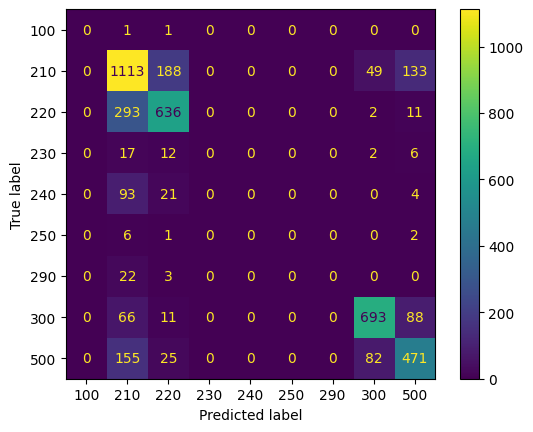

In [30]:
labels = sorted(set(y_val))
cm = confusion_matrix(y_val, val_y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=labels)
disp.plot()
plt.show()

Finally, let's consider the topic of *interpretability*. That is, how easy is it to understand the reasoning behind a model's decisions. When you use a large number of trees, it is technically possible to understand exactly how decisions are made by analyzing the splits in each trees. However, this is a very time-consuming task, and not realistic to do in almost any scenario. How then can we make sense of our predictions, while still making use of its complex, non-linear performance benefits?

RF models have a built-in trick in the form of *node purity*.

Entropy is based on information theory. It quantifies the uncertainty or impurity in a set of data. A node with high entropy has a mix of different classes (high disorder), while a node with low entropy is more homogeneous (low disorder). In this context, a higher value means that removing the variable causes more disorder, so therefore the class is more important.

Gini coefficient (or Gini impurity) measures the probability of incorrectly classifying a randomly chosen element if it was randomly labeled according to the distribution of classes in the node. Like entropy, a higher Gini impurity for a given variable indicates that it is more important for the predictions of the model.

For more information, please have a look at the book [Introduction to Statistical Learning](https://www.stat.berkeley.edu/users/rabbee/s154/ISLR_First_Printing.pdf), page 312 discusses these metrics.

In [36]:
## We train two models with the same parameter settings - one for entropy, and one for the GINI coefficient.
entropy_model = RandomForestClassifier(n_estimators=100, min_samples_split=10, max_depth=25, criterion='entropy')
entropy_model.fit(x_train.values, y_train.values)
features_entropy = entropy_model.feature_importances_

gini_model = RandomForestClassifier(n_estimators=100, min_samples_split=10, max_depth=25, criterion='gini')
gini_model.fit(x_train.values, y_train.values)
features_gini = gini_model.feature_importances_

Let's plot the results for the model trained using both of these metrics.

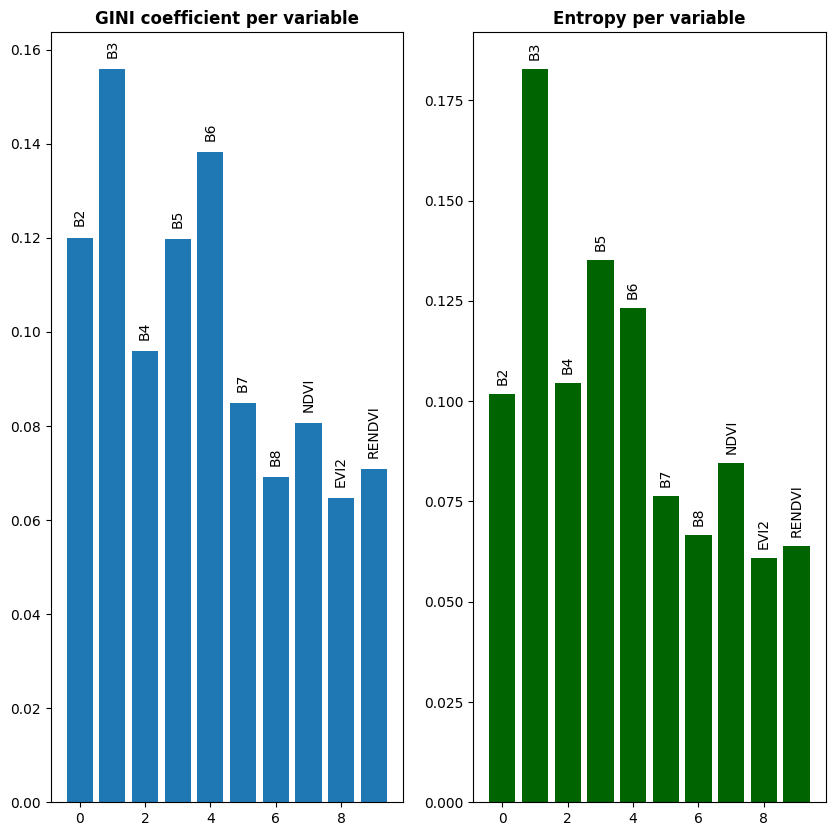

In [37]:
## Make bar plots
x_axis = range(len(features_gini))
fig, (ax_gini, ax_entropy) = plt.subplots(1, 2, figsize=(10,10))
ax_gini.bar(x_axis, features_gini)
ax_gini.set_title("GINI coefficient per variable", weight='bold')
ax_entropy.bar(x_axis, features_entropy, color='darkgreen')
ax_entropy.set_title("Entropy per variable", weight='bold')

## Add labels to the bars
for index, label in enumerate(img_bands):
    ax_gini.text(index, y=features_gini[index]+0.003, s=label, ha='center', rotation=90)
for index, label in enumerate(img_bands):
    ax_entropy.text(index, y=features_entropy[index]+0.003, s=label, ha='center', rotation=90)

In [38]:
entropy_pred = entropy_model.predict(x_val)

print("Entropy accuracy:", accuracy_score(y_val, entropy_pred))
print("Entropy Kappa:", cohen_kappa_score(y_val, entropy_pred))


gini_pred = gini_model.predict(x_val)

print("Gini accuracy:", accuracy_score(y_val, gini_pred))
print("Gini Kappa:", cohen_kappa_score(y_val, gini_pred))

Entropy accuracy: 0.6928927977180889
Entropy Kappa: 0.5828624579251194
Gini accuracy: 0.6964582838126931
Gini Kappa: 0.5877622689385272


# 6. Measuring test set performance
---
In this section you will use what you have learned before to run the model again on a new test area. You're in the driver's seat now - look back on how we've defined steps earlier, it will help you out.

We've trained and validated several models, now it's time to find out how they perform when we provide it with new data one last time. This is called model <mark>testing</mark>. We go through this step only once, and this is generally the metrics that we add to the paper. It's because we used the validation set to find a set of parameters that should work well on new data, so we shouldn't then fine-tune on top of the test set.

So let's re-make our dataset by using a diffent province. In our example we will be using Zeeland as a new region for the trained model to predict on. You're free to define the model as you like.

In [39]:
## Here, perform the following steps, or re-use the model you already came up with.

## 1. Initialize a random forest classifier
## 2. Use the best parameters from your hyperparameter grid search
## 3. Train a model on the training dataset - otherwise you start predicting with a random model

model = RandomForestClassifier(n_estimators=n_trees, min_samples_split=min_samples, max_depth=25)

test_model = RandomForestClassifier(n_estimators=250, min_samples_split=10, max_depth=10, criterion='gini')
test_model.fit(x_train.values, y_train.values)
features_test = test_model.feature_importances_

**Load test set sample data in Zeeland**

In [41]:
zeeland = ee.FeatureCollection('FAO/GAUL/2015/level1') \
    .filter(ee.Filter.eq('ADM0_NAME', 'Netherlands')) \
    .filter(ee.Filter.eq('ADM1_NAME', 'Zeeland'))
Map = geemap.Map(height=800, width=700, zoom=10, basemap='HYBRID')

flevoland = ee.FeatureCollection('FAO/GAUL/2015/level1') \
    .filter(ee.Filter.eq('ADM0_NAME', 'Netherlands')) \
    .filter(ee.Filter.eq('ADM1_NAME', 'Flevoland'))

Map = geemap.Map(center=[52.5, 5.5], height=800, width=700, zoom=10, basemap='HYBRID')

In [ ]:
# Load Sentinel-2 SR imagery
sentinel_test = (ee.ImageCollection(...

# Create median composite and clip to Flevoland
sentinel_composite_test = sentinel_test.median()

# Visualization parameters (RGB)
vis_params = {
    'min': 0.0,
    'max': 0.3,
    'bands': ...
}

Map_test.addLayer(sentinel_composite_test, vis_params, 'S2 Test RGB (2018)')
Map_test

Add indices - you can add your own indices if you like.

In [ ]:
...

# Add indices to composite
test_img = sentinel_composite_test.addBands([...])

Load crop map over area and reclassify

In [ ]:
# Load and clip EUCROPMAP 2018
cropmap_test = ...

cropmap_test_reclassed = ...
Map_test.addLayer(cropmap_test, {}, 'EUCROPMAP 2018')
Map_test.centerObject(zeeland, 9)
Map_test

**Sample reference points**

In [ ]:
reference_points_test = ... # Remember to crop it to the right region!

Make test dataset

In [ ]:
test_data = test_img.select(img_bands).sampleRegions(
    **{'collection': reference_points_test, 'properties': [label_col], 'scale': 10}
)
x_test, y_test = feature_collection_to_lists(test_data, img_bands, label_col)

We already have our trained model, and we're not supposed to re-train it on this image. Therefore, all that's left to do is to run this model and test its performance on this new dataset.

In [ ]:
## Use the model to predict all of the validation pixels and to print metrics
test_y_pred = ...

Lastly, let's quickly take a look at the classification for the entire area. For this, we re-train the model using packages built into GEE, such that we don't have to convert data back and forth. We can do it with SKLearn, but this is a quicker and much more optimized method for the way we're working.

This will also show you how much Google Earth Engine has streamlined the pipeline of working with satellite data!

In [ ]:
# Cast labels into floats, otherwise GEE refuses to work with it
def convert_to_float(feature):
    return feature.set(label_col, ee.Number.parse(feature.get(label_col)))

train_data = train_data.map(convert_to_float)
test_data = test_data.map(convert_to_float)

In [ ]:
# Train the model on the training dataset
classifier = ee.Classifier.smileRandomForest(numberOfTrees=250, minLeafPopulation=2, maxNodes=25)
trained_classifier = classifier.train(features=train_data, classProperty=label_col, inputProperties=img_bands)

# Apply the classifier to the test data
classified_test = test_data.classify(trained_classifier)

Now, let's visualize it by defining an updated class legend for the EUCROPMAP dataset

In [ ]:
# Classify the test image
classified_image = test_img.classify(trained_classifier)

colour_dict = {
    100: "#ffffff",     # urban
    210: "#ffd300",     # Cereals
    220: "#a800e2",     # Root crops
    230: "#ffff00",     # Industrial crops
    240: "#f2a377",     # Leguminous crops
    250: "#e8bfff",     # Fodder crops
    290: "#696969",     # Bare arable land
    300: "#93cc93",     # Wood/shrubland
    500: "#e8ffbf",     # Grassland
}

# Convert string labels to numeric codes
def classify_to_numeric(image):
    # Create a dictionary that maps string labels to numeric values
    label_to_numeric = {label: index for index, label in enumerate(colour_dict.keys())}

    # Convert string label to numeric value
    return image.remap(
        list(label_to_numeric.keys()),
        list(label_to_numeric.values())
    )

# Convert the classified image
numeric_classified_image = classify_to_numeric(classified_image)

# Generate a palette for visualization
palette = [colour_dict[label] for label in colour_dict.keys()]

In [ ]:
# Add the numeric classified image to the map
Map_test.addLayer(numeric_classified_image, {'palette': palette, 'min': 0, 'max': len(colour_dict) - 1}, 'Classified Image')
Map_test

In principle, the model's results on the test set are what we would report in a paper. Depending on your expectations, you might be surprised with the results of the model compared to the test set. However, it's important to remember a few things:
1.  We haven't played around much with the input variables. There are more tricks that we could tap into that we haven't discussed (e.g. think about how important it is to see what happens around a pixel in order to determine what's happening inside of it).
2.  This is a **hard** task for a simple model as we're dealing with similar classes, and a vague and uncertain reference data definition.
3.  We are not consistent with the time of year at which we're predicting, which for some crop cover classes has a large impact on how it's perceived.
4.  We're training it on just 25'000 pixels. This is a limited amount for a hard task, and usually we'd prefer to use much more data.

And there's many more reasons we could list. The reality is that modelling is a hard task, and a lot of the trial-and-error and failed models get underreported in papers. By showing you the harsh realities of real-life, difficult modelling problems, we hope to have demonstrated that this type of modelling has strong potential, but also that it doesn't come easy. With that in mind, let's reflect a little bit on how we can do better. Please answer the question below, and we will provide feedback and discuss some of the answers.

❗**Q12 (6 points): [Have a look at more recent papers on crop type classification](https://scholar.google.com/scholar?as_ylo=2021&q=crop+type+classification+using+remote+sensing&hl=en&as_sdt=0,5). Skim some abstracts, conclusion sections, and maybe the methodology section if the paper catches your attention. Which trends exist in the field currently, and which take-aways can you use to apply to the prediction case you worked on in this tutorial?**

## Wrapping up
That's it for this practical. There's many more nuances we could get into, but we'd need another lecture or two if we want to cover them all. Hopefully this practical gave you some insights into what it means to run a machine learning pipeline. We also hope that you see now that machine learning isn't a fully-automatic magical problem-solving box, but that there are quite a lot of steps involved and decisions to make. It's up to you, the modeller, to make the right choices with regards to data set-up and model parameter choices. Since this tutorial is getting lengthy already, we unfortunately can't go into more detail on how to improve the model further, especially on the test set. We will provide feedback based on the questions, and provide general tips on what makes a successful ML pipeline. We also hope that this tutorial inspires you to look deeper into modelling, while retaining a critical outlook on what it is and what it can do!

and, remember...

> *All models are wrong, some are useful*

*George Box, 1976*
